# Music & Mental Health — Notebook 02: Features, listener personas and research-grade modelling

**Purpose.** Notebook 01 showed that genre frequency has small, mostly age-confounded associations with the four self-reported conditions. Here we ask three further questions, always with honest uncertainty:

1. Do listeners fall into **distinct taste personas**, and do those personas differ on the four conditions?
2. How much do **music habits and genre mix add** over a trivial age-and-hours baseline when predicting each condition (as a 0–10 score and as a "high" ≥ 7 flag)?
3. Which features carry **stable** signal, and which genre-condition hypotheses are worth testing in a controlled medical study?

**Design safeguards**
- A 20% **hold-out test set** is split off first and touched only once for pre-listed comparisons.
- All imputation and scaling happen **inside cross-validation pipelines**, so nothing leaks.
- The primary models (ridge / logistic regression) were **pre-specified**; random forest and gradient boosting are sensitivity checks, not a fishing expedition.
- Model differences use the **Nadeau–Bengio corrected t-test**, since repeated-CV folds overlap.
- `Music effects` (self-reported outcome of listening) is **excluded** from all features.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, adjusted_rand_score, roc_auc_score, r2_score,
                             average_precision_score, brier_score_loss)
from sklearn.model_selection import (train_test_split, cross_val_predict, StratifiedKFold, RepeatedKFold)
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().resolve()
while not (ROOT / 'src').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from mxmh.config import SEED, TARGETS, GENRES, FREQ_COLS
from mxmh.data import load_raw, clean_data
from mxmh.features import FEATURE_SETS, make_preprocessor
from mxmh.modeling import (regressors, classifiers, make_pipeline, cv_compare, nadeau_bengio, bootstrap_metric)

TAB, FIG = ROOT / 'reports' / 'tables', ROOT / 'reports' / 'figures'
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
for needed in ('genre_condition_effects.csv', 'genre_condition_adjusted.csv'):
    assert (TAB / needed).exists(), f'Run notebook 01 first (missing {needed})'

sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(SEED)
df, _ = clean_data(load_raw(ROOT / 'data' / 'raw' / 'mxmh_survey_results.csv'))
df['hours'] = df['Hours per day']
print(df.shape)

(736, 39)


## 1. Genre structure with PCA (descriptive)

PCA on the 16 standardised genre-frequency columns shows how much taste varies along a few broad axes. It is used for description only (not as a model input), so it cannot leak anything.

Variance explained by first 4 components: [0.206 0.127 0.102 0.09 ] | cumulative: 0.525


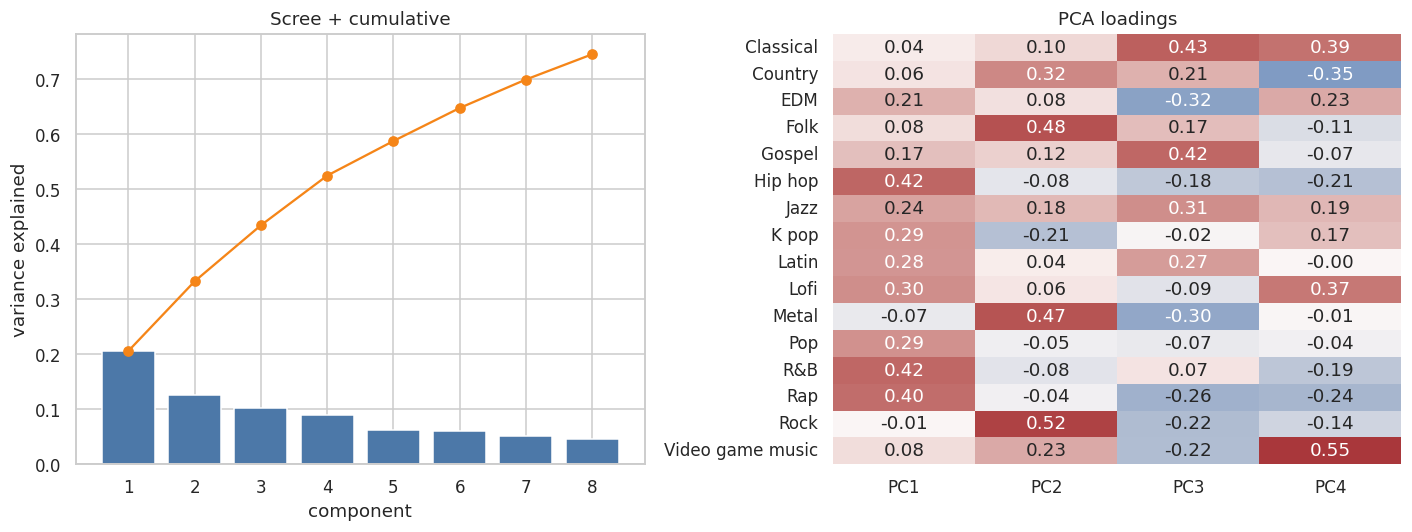

PC1 | negative: Metal, Rock, Classical | positive: Rap, R&B, Hip hop
PC2 | negative: K pop, R&B, Hip hop | positive: Metal, Folk, Rock
PC3 | negative: EDM, Metal, Rap | positive: Jazz, Gospel, Classical
PC4 | negative: Country, Rap, Hip hop | positive: Lofi, Classical, Video game music


In [2]:
Z = StandardScaler().fit_transform(df[FREQ_COLS])
pca = PCA().fit(Z)
ev = pca.explained_variance_ratio_
print('Variance explained by first 4 components:', ev[:4].round(3), '| cumulative:', ev[:4].sum().round(3))
load = pd.DataFrame(pca.components_[:4].T, index=GENRES, columns=[f'PC{i+1}' for i in range(4)])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(range(1, 9), ev[:8], color='#4C78A8'); ax[0].plot(range(1, 9), np.cumsum(ev[:8]), 'o-', color='#F58518')
ax[0].set_xlabel('component'); ax[0].set_ylabel('variance explained'); ax[0].set_title('Scree + cumulative')
sns.heatmap(load, cmap='vlag', center=0, annot=True, fmt='.2f', ax=ax[1], cbar=False); ax[1].set_title('PCA loadings')
plt.tight_layout(); fig.savefig(FIG / 'pca_genres.png', dpi=150); plt.show()
for pc in load.columns:
    s = load[pc].sort_values()
    print(pc, '| negative:', ', '.join(s.index[:3]), '| positive:', ', '.join(s.index[-3:]))

## 2. Listener personas (k-means on genre frequencies)

For each k from 3 to 6 we report the silhouette score and a **bootstrap stability** score (adjusted Rand index between the full-data clustering and clusterings refit on bootstrap resamples). We take the k with the highest silhouette among stable solutions (ARI ≥ 0.6). If none is stable we still pick the best silhouette but flag the structure as weak, because clustering algorithms always return clusters, whether or not they are real.

In [3]:
Zg = StandardScaler().fit_transform(df[FREQ_COLS])
rows = []
for k in range(3, 7):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Zg)
    sil = silhouette_score(Zg, km.labels_)
    aris = []
    for b in range(50):
        idx = rng.integers(0, len(Zg), len(Zg))
        kb = KMeans(k, n_init=5, random_state=b).fit(Zg[idx])
        aris.append(adjusted_rand_score(km.labels_, kb.predict(Zg)))
    rows.append({'k': k, 'silhouette': sil, 'stability_ARI': np.mean(aris), 'ARI_sd': np.std(aris)})
ktab = pd.DataFrame(rows); display(ktab.round(3))
stable = ktab[ktab.stability_ARI >= 0.6]
best_k = int((stable if len(stable) else ktab).sort_values('silhouette', ascending=False).k.iloc[0])
weak = len(stable) == 0
print('Chosen k =', best_k, '| structure flagged WEAK' if weak else '| stable solution')

,k,silhouette,stability_ARI,ARI_sd
0,3,0.117,0.817,0.107
1,4,0.091,0.588,0.129
2,5,0.088,0.527,0.119
3,6,0.091,0.517,0.108


Chosen k = 3 | stable solution


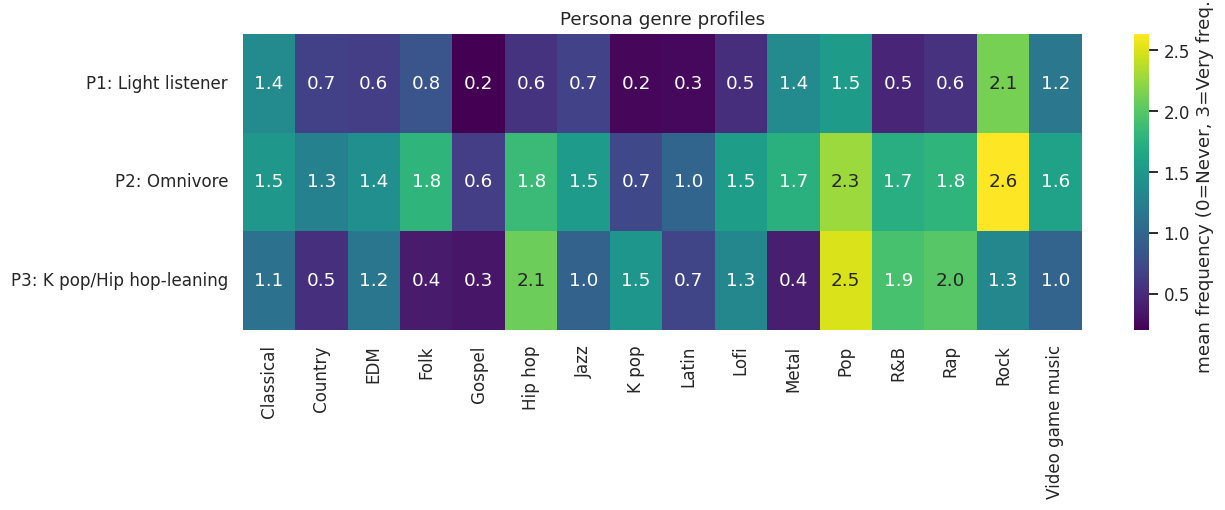

,n,mean_age,mean_hours,genre_diversity,pct_instrumentalist
persona,,,,,
P1: Light listener,302,27.10,3.00,3.91,0.38
P2: Omnivore,233,25.75,4.02,8.32,0.33
P3: K pop/Hip hop-leaning,201,21.72,3.45,6.18,0.21


In [4]:
km = KMeans(best_k, n_init=50, random_state=SEED).fit(Zg)
cz = pd.DataFrame(km.cluster_centers_, columns=GENRES)
order = pd.Series(km.labels_).value_counts().index.tolist()     # largest persona first
def persona_name(i):
    r = cz.loc[i]
    if r.mean() > 0.35: return 'Omnivore'
    if r.max() < 0.25: return 'Light listener'
    a, b = r.nlargest(2).index
    return f'{a}/{b}-leaning'
id_map = {c: f'P{j+1}' for j, c in enumerate(order)}
name_map = {id_map[c]: f'P{j+1}: {persona_name(c)}' for j, c in enumerate(order)}
df['persona_id'] = pd.Series(km.labels_).map(id_map).values
df['persona'] = df['persona_id'].map(name_map)

prof = df.groupby('persona')[FREQ_COLS].mean(); prof.columns = GENRES
fig, ax = plt.subplots(figsize=(12, 3 + 0.6 * best_k))
sns.heatmap(prof, cmap='viridis', annot=True, fmt='.1f', ax=ax, cbar_kws={'label': 'mean frequency (0=Never, 3=Very freq.)'})
ax.set_ylabel(''); ax.set_title('Persona genre profiles'); plt.tight_layout(); fig.savefig(FIG / 'personas_profile.png', dpi=150); plt.show()

desc = df.groupby('persona').agg(n=('Age', 'size'), mean_age=('Age', 'mean'), mean_hours=('hours', 'mean'),
                                  genre_diversity=('genre_diversity', 'mean'), pct_instrumentalist=('Instrumentalist', 'mean'))
display(desc.round(2))

### Do personas differ on the four conditions?

Kruskal–Wallis test with the epsilon-squared effect size (≈ share of rank variance explained by persona), plus an **age- and hours-adjusted** Wald test, since personas differ in age.

,condition,KW_H,p_raw,epsilon_sq,p_adjusted_age_hours,q_fdr_raw,q_fdr_adjusted
0,Anxiety,8.0411,0.0179,0.0082,0.0039,0.0239,0.0077
1,Depression,19.2418,0.0001,0.0235,0.0001,0.0003,0.0005
2,Insomnia,12.2243,0.0022,0.0139,0.0060,0.0044,0.0079
3,OCD,1.2883,0.5251,-0.0010,0.4499,0.5251,0.4499


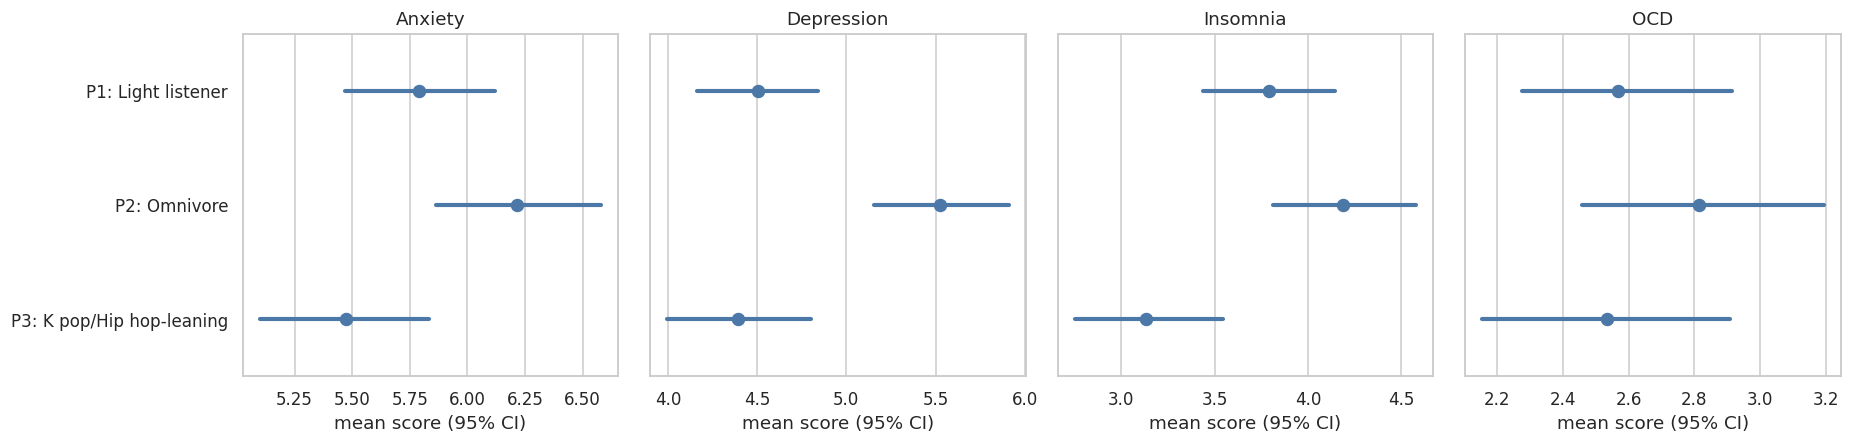

In [5]:
rows = []
k = df.persona_id.nunique()
for t in TARGETS:
    groups = [g[t].values for _, g in df.groupby('persona_id')]
    H, p = stats.kruskal(*groups)
    eps2 = (H - k + 1) / (len(df) - k)
    m = smf.ols(f'{t} ~ C(persona_id) + Age + hours', data=df).fit(cov_type='HC3')
    names = [n for n in m.params.index if 'persona_id' in n]
    Rm = np.zeros((len(names), len(m.params)))
    for i, n in enumerate(names): Rm[i, list(m.params.index).index(n)] = 1
    p_adj = float(m.wald_test(Rm, scalar=True).pvalue)
    rows.append({'condition': t, 'KW_H': H, 'p_raw': p, 'epsilon_sq': eps2, 'p_adjusted_age_hours': p_adj})
pers = pd.DataFrame(rows)
pers['q_fdr_raw'] = multipletests(pers.p_raw, method='fdr_bh')[1]
pers['q_fdr_adjusted'] = multipletests(pers.p_adjusted_age_hours, method='fdr_bh')[1]
display(pers.round(4)); pers.round(4).to_csv(TAB / 'persona_tests.csv', index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, t in zip(axes, TARGETS):
    sns.pointplot(data=df, y='persona', x=t, order=sorted(name_map.values()), errorbar=('ci', 95), color='#4C78A8', linestyle='none', ax=ax)
    ax.set_title(t); ax.set_ylabel(''); ax.set_xlabel('mean score (95% CI)')
plt.tight_layout(); fig.savefig(FIG / 'personas_conditions.png', dpi=150); plt.show()

## 3. Modelling set-up

- **Split.** 80% train / 20% hold-out test, stratified on `Depression_high`.
- **Feature sets** (nested complexity): baseline (age, hours) → habits → genres only → habits + genres → plus favourite genre and streaming service.
- **Targets.** Each condition as a 0–10 regression, and as a binary "high" (≥ 7) flag.
- **Primary models** (pre-specified): `RidgeCV` and `LogisticRegressionCV`. **Sensitivity:** random forest and gradient boosting, kept deliberately shallow because n is small.
- **CV.** 5-fold × 2 repeats on the training set, identical folds for every feature set, so differences are paired.

In [6]:
train, test = train_test_split(df, test_size=0.2, stratify=df['Depression_high'], random_state=SEED)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
print('train', train.shape, '| test', test.shape)
print('Prevalence of "high" (>=7), train:', {t: round(train[f'{t}_high'].mean(), 3) for t in TARGETS})

train (588, 41) | test (148, 41)
Prevalence of "high" (>=7), train: {'Anxiety': np.float64(0.485), 'Depression': np.float64(0.349), 'Insomnia': np.float64(0.228), 'OCD': np.float64(0.146)}


In [7]:
t0 = time.time()
frames = [cv_compare(train, t, task, n_splits=5, n_repeats=2) for t in TARGETS for task in ('regression', 'classification')]
cv = pd.concat(frames, ignore_index=True)
cv.to_csv(TAB / 'cv_fold_scores.csv', index=False)
print(f'cross-validation done in {time.time() - t0:.0f}s, {len(cv)} fold scores')

cross-validation done in 122s, 1600 fold scores


### 3.1 Does music information add anything over age and hours?

Each row compares a feature set to the baseline using the primary model. The `diff` is the mean per-fold gain (R² for regression, AUROC for classification), with a Nadeau–Bengio corrected p-value and FDR correction across all comparisons.

In [8]:
n_tr = len(train); n_te = n_tr // 5
base_name = list(FEATURE_SETS)[0]
rows = []
for task, primary, metric in (('regression', 'ridge', 'r2'), ('classification', 'logistic', 'auroc')):
    for t in TARGETS:
        sel = cv[(cv.task == task) & (cv.target == t) & (cv.model == primary)]
        base = sel[sel.feature_set == base_name].sort_values('fold')[metric].values
        for fs in FEATURE_SETS:
            v = sel[sel.feature_set == fs].sort_values('fold')[metric].values
            d, tt, p = nadeau_bengio(v - base, n_tr - n_te, n_te)
            rows.append({'task': task, 'metric': metric, 'target': t, 'feature_set': fs,
                         'cv_mean': v.mean(), 'cv_sd': v.std(ddof=1), 'diff_vs_baseline': d, 'p_NB': p})
cmp = pd.DataFrame(rows)
mask = cmp.feature_set != base_name
cmp.loc[mask, 'q_fdr'] = multipletests(cmp.loc[mask, 'p_NB'], method='fdr_bh')[1]
cmp.round(4).to_csv(TAB / 'cv_feature_set_comparison.csv', index=False)
for task in ('regression', 'classification'):
    print(f'--- {task} ({cmp[cmp.task == task].metric.iloc[0]}, primary model) ---')
    display(cmp[cmp.task == task].pivot(index='feature_set', columns='target', values='cv_mean').loc[list(FEATURE_SETS)].round(3))
print('Gain over baseline, only rows with nominal p<0.05:')
display(cmp[mask & (cmp.p_NB < 0.05)].round(4).reset_index(drop=True))

--- regression (r2, primary model) ---


target,Anxiety,Depression,Insomnia,OCD
feature_set,,,,
"baseline (age, hours)",0.026,0.014,0.015,0.017
habits,0.007,0.004,0.014,0.002
genres only,-0.001,0.040,0.009,-0.010
habits + genres,0.012,0.044,0.021,-0.001
habits + genres + categorical,0.014,0.050,0.020,0.000


--- classification (auroc, primary model) ---


target,Anxiety,Depression,Insomnia,OCD
feature_set,,,,
"baseline (age, hours)",0.564,0.575,0.629,0.564
habits,0.536,0.564,0.628,0.465
genres only,0.566,0.593,0.603,0.490
habits + genres,0.569,0.599,0.615,0.479
habits + genres + categorical,0.564,0.605,0.615,0.455


Gain over baseline, only rows with nominal p<0.05:


,task,metric,target,feature_set,cv_mean,cv_sd,diff_vs_baseline,p_NB,q_fdr
0,regression,r2,Anxiety,habits,0.0075,0.0348,-0.0185,0.0341,0.3073
1,regression,r2,OCD,habits,0.0018,0.0148,-0.0150,0.0435,0.3073
2,classification,auroc,OCD,habits,0.4648,0.0674,-0.0995,0.0443,0.3073
3,classification,auroc,OCD,habits + genres + categorical,0.4550,0.0581,-0.1093,0.0402,0.3073


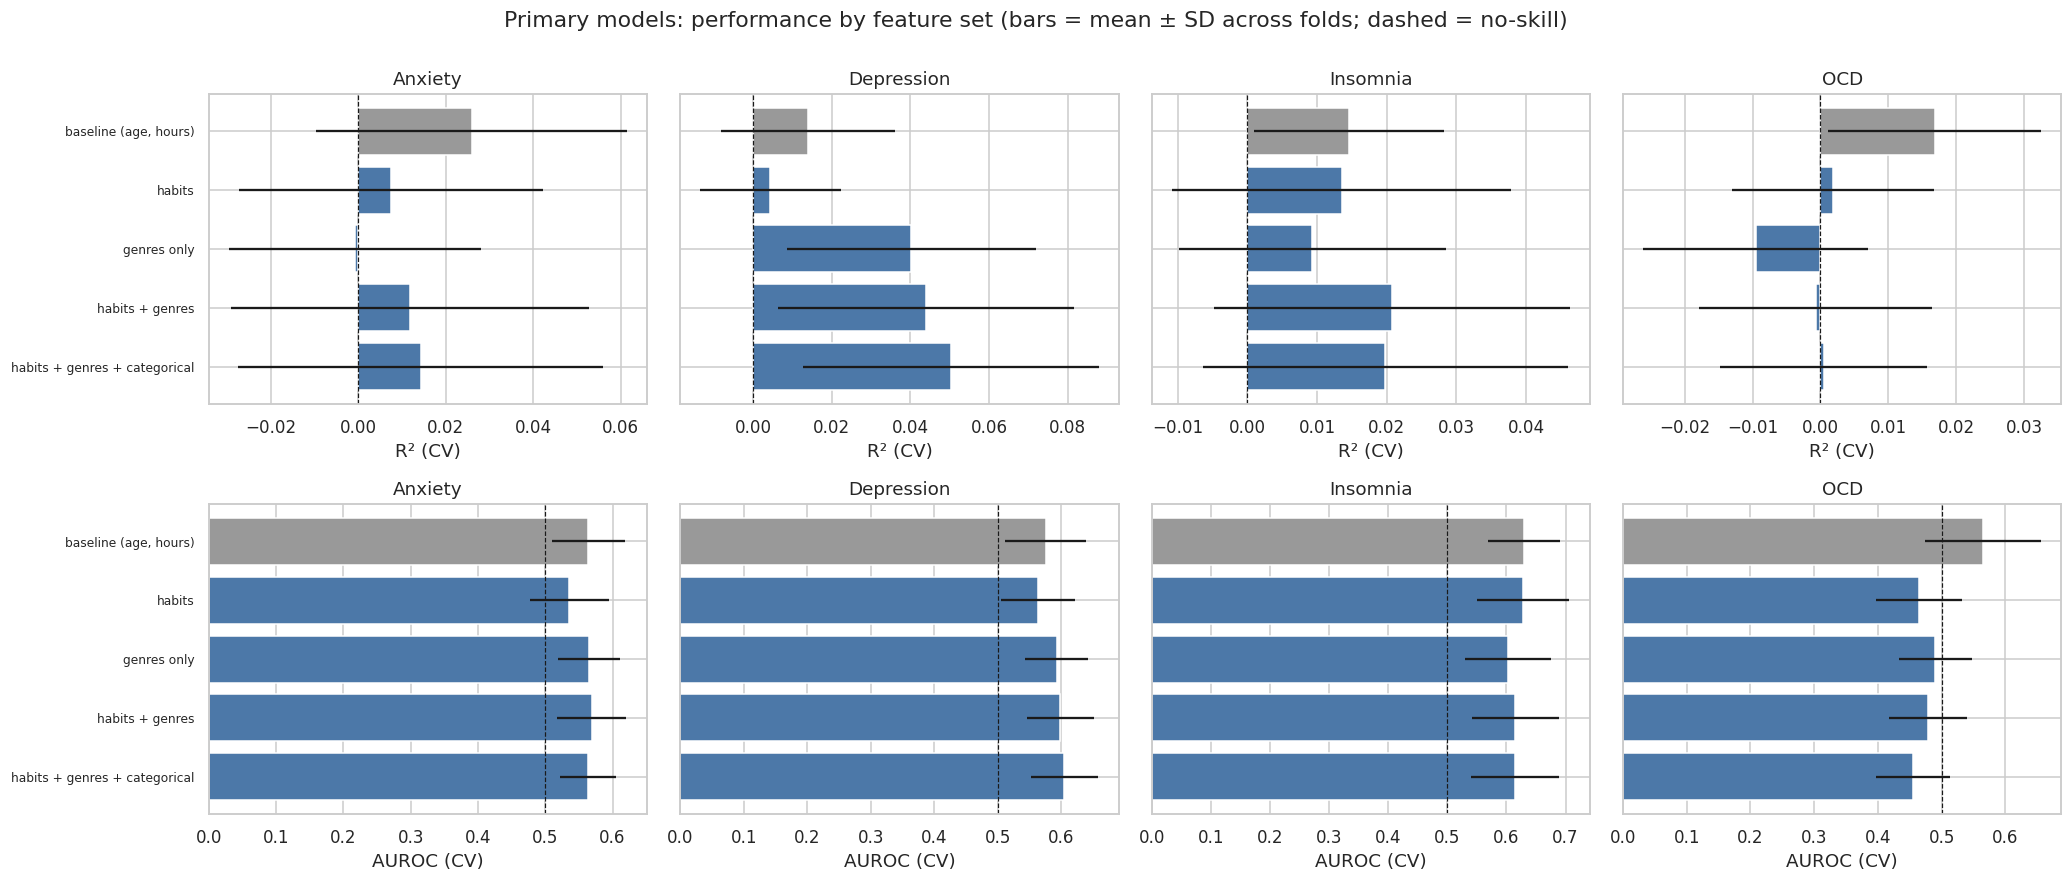

In [9]:
fs_order = list(FEATURE_SETS)
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for row, (task, primary, metric, lab) in enumerate((('regression', 'ridge', 'r2', 'R² (CV)'), ('classification', 'logistic', 'auroc', 'AUROC (CV)'))):
    for j, t in enumerate(TARGETS):
        d = cv[(cv.task == task) & (cv.target == t) & (cv.model == primary)].groupby('feature_set')[metric].agg(['mean', 'std']).loc[fs_order]
        ax = axes[row, j]
        ax.barh(range(len(d)), d['mean'], xerr=d['std'], color=['#999999'] + ['#4C78A8'] * (len(d) - 1))
        ax.axvline(0 if row == 0 else 0.5, color='k', lw=0.8, ls='--')
        ax.set_yticks(range(len(d))); ax.set_yticklabels(fs_order if j == 0 else [], fontsize=8)
        ax.invert_yaxis(); ax.set_title(f'{t}'); ax.set_xlabel(lab)
plt.suptitle('Primary models: performance by feature set (bars = mean ± SD across folds; dashed = no-skill)', y=1.0)
plt.tight_layout(); fig.savefig(FIG / 'cv_feature_sets.png', dpi=150); plt.show()

### 3.2 Are non-linear models any better? (sensitivity check)

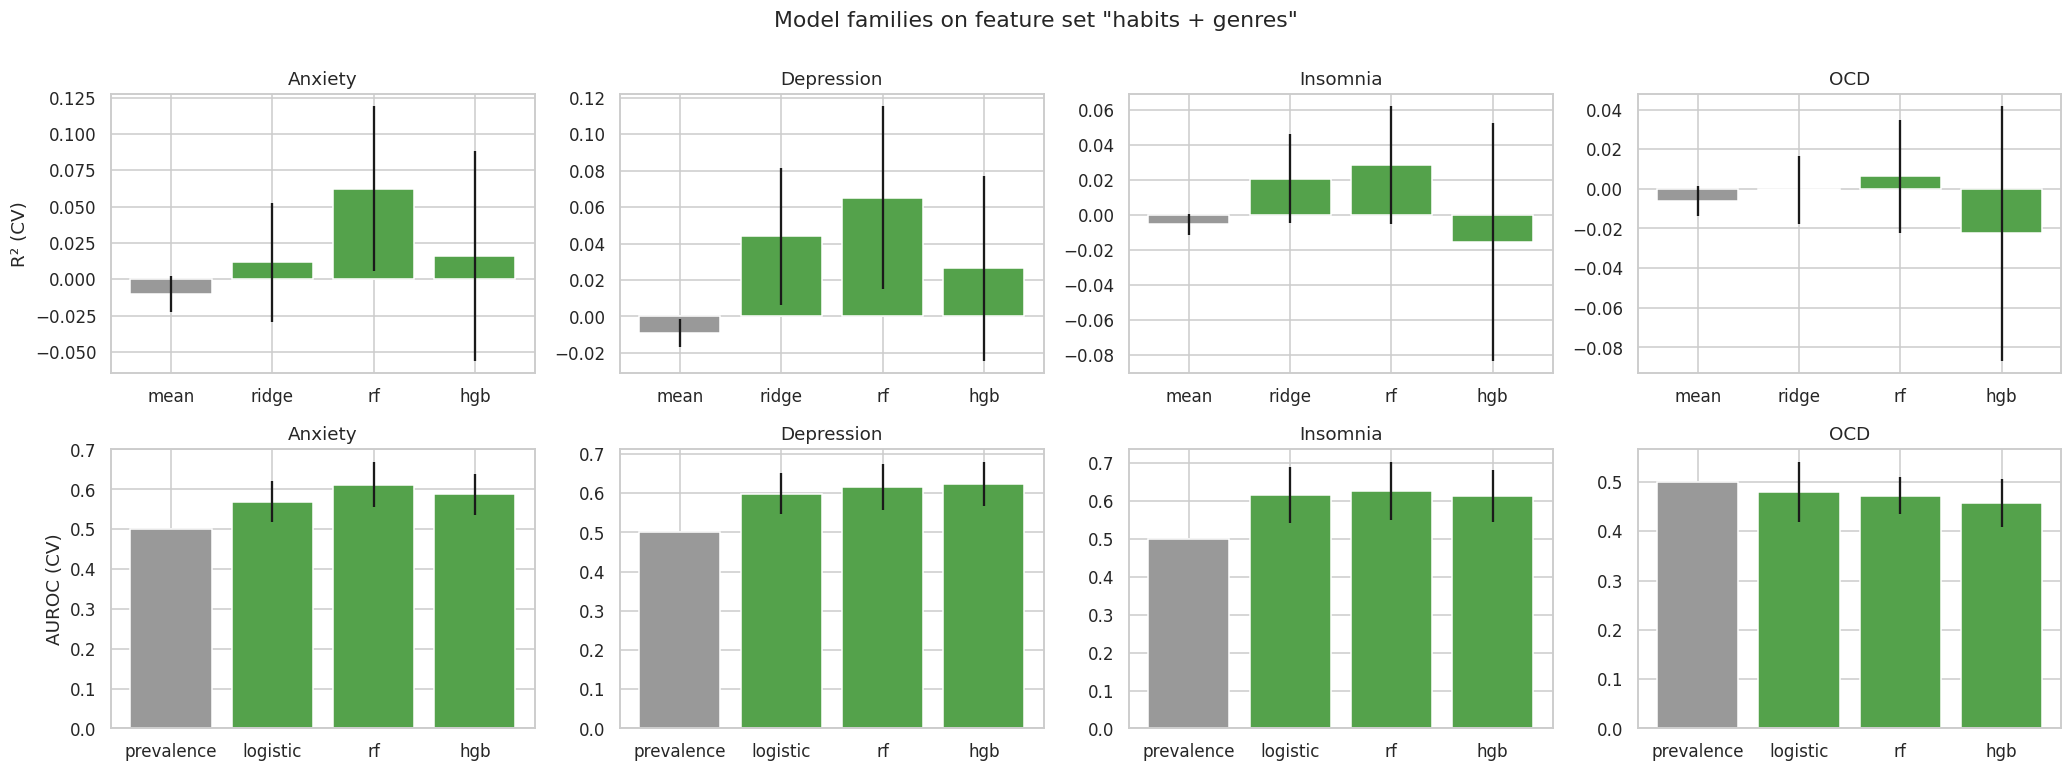

r2  auroc
task           target     model                   
classification Anxiety    hgb           NaN  0.587
                          logistic      NaN  0.569
                          prevalence    NaN  0.500
                          rf            NaN  0.612
               Depression hgb           NaN  0.623
                          logistic      NaN  0.599
                          prevalence    NaN  0.500
                          rf            NaN  0.616
               Insomnia   hgb           NaN  0.613
                          logistic      NaN  0.615
                          prevalence    NaN  0.500
                          rf            NaN  0.625
               OCD        hgb           NaN  0.458
                          logistic      NaN  0.479
                          prevalence    NaN  0.500
                          rf            NaN  0.472
regression     Anxiety    hgb         0.016    NaN
                          mean       -0.010    NaN
                          rf          0.062    NaN
                          ridge       0.012    NaN
               Depression hgb         0.026    NaN
                          mean       -0.009    NaN
                          rf          0.065    NaN
                          ridge       0.044    NaN
               Insomnia   hgb        -0.015    NaN
                          mean       -0.005    NaN
                          rf          0.029    NaN
                          ridge       0.021    NaN
               OCD        hgb        -0.022    NaN
                          mean       -0.006    NaN
                          rf          0.006    NaN
                          ridge      -0.001    NaN

In [10]:
fs = 'habits + genres'
fig, axes = plt.subplots(2, 4, figsize=(19, 7))
for row, (task, metric, order, lab) in enumerate((('regression', 'r2', ['mean', 'ridge', 'rf', 'hgb'], 'R² (CV)'),
                                                  ('classification', 'auroc', ['prevalence', 'logistic', 'rf', 'hgb'], 'AUROC (CV)'))):
    for j, t in enumerate(TARGETS):
        d = cv[(cv.task == task) & (cv.target == t) & (cv.feature_set == fs)].groupby('model')[metric].agg(['mean', 'std']).loc[order]
        ax = axes[row, j]
        ax.bar(order, d['mean'], yerr=d['std'], color=['#999999'] + ['#54A24B'] * 3)
        ax.set_title(t); ax.set_ylabel(lab if j == 0 else '')
plt.suptitle(f'Model families on feature set "{fs}"', y=1.0); plt.tight_layout()
fig.savefig(FIG / 'cv_model_families.png', dpi=150); plt.show()
mf = cv[cv.feature_set == fs].groupby(['task', 'target', 'model'])[['r2', 'auroc']].mean().round(3)
display(mf.dropna(how='all'))

## 4. Hold-out test (used once, for pre-listed comparisons only)

Models are refit on the full training set and scored on the 148 unseen respondents, with 95% bootstrap CIs. A CI that includes the no-skill value (R² = 0, AUROC = 0.5) means the model is not distinguishable from guessing on this sample.

In [11]:
def holdout_rows():
    out = []
    for t in TARGETS:
        for fs in (base_name, 'habits + genres', 'habits + genres + categorical'):
            cols = FEATURE_SETS[fs]
            for mname in ('ridge', 'rf'):
                p = make_pipeline(cols, regressors()[mname]).fit(train[cols], train[t])
                pred = p.predict(test[cols])
                r, lo, hi = bootstrap_metric(test[t], pred, r2_score)
                out.append({'target': t, 'task': 'regression', 'feature_set': fs, 'model': mname,
                            'metric': 'R2', 'value': r, 'ci_lo': lo, 'ci_hi': hi})
            for mname in ('logistic', 'rf'):
                p = make_pipeline(cols, classifiers()[mname]).fit(train[cols], train[f'{t}_high'])
                pr = p.predict_proba(test[cols])[:, 1]
                a, lo, hi = bootstrap_metric(test[f'{t}_high'], pr, roc_auc_score)
                out.append({'target': t, 'task': 'classification', 'feature_set': fs, 'model': mname,
                            'metric': 'AUROC', 'value': a, 'ci_lo': lo, 'ci_hi': hi})
    return pd.DataFrame(out)
ho = holdout_rows(); ho.round(4).to_csv(TAB / 'holdout_results.csv', index=False)
ho['result'] = ho.apply(lambda r: f"{r.value:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]", axis=1)
for task, m in (('regression', 'R2'), ('classification', 'AUROC')):
    print(f'--- hold-out {m} [95% CI] ---')
    display(ho[ho.task == task].pivot_table(index=['feature_set', 'model'], columns='target', values='result', aggfunc='first')[TARGETS])

--- hold-out R2 [95% CI] ---


target                                              Anxiety  \
feature_set                   model                           
baseline (age, hours)         rf     -0.077 [-0.222, 0.048]   
                              ridge  -0.016 [-0.134, 0.082]   
habits + genres               rf     -0.057 [-0.219, 0.062]   
                              ridge  -0.014 [-0.115, 0.059]   
habits + genres + categorical rf     -0.066 [-0.225, 0.057]   
                              ridge  -0.015 [-0.117, 0.060]   

target                                          Depression  \
feature_set                   model                          
baseline (age, hours)         rf     0.040 [-0.087, 0.132]   
                              ridge  0.035 [-0.040, 0.095]   
habits + genres               rf     0.054 [-0.059, 0.143]   
                              ridge  0.031 [-0.061, 0.108]   
habits + genres + categorical rf     0.051 [-0.057, 0.136]   
                              ridge  0.009 [-0.098, 0.102]   

target                                             Insomnia  \
feature_set                   model                           
baseline (age, hours)         rf     -0.069 [-0.196, 0.023]   
                              ridge  -0.024 [-0.126, 0.037]   
habits + genres               rf     -0.014 [-0.130, 0.066]   
                              ridge  -0.020 [-0.126, 0.044]   
habits + genres + categorical rf     -0.019 [-0.136, 0.064]   
                              ridge  -0.018 [-0.118, 0.038]   

target                                                   OCD  
feature_set                   model                           
baseline (age, hours)         rf      -0.038 [-0.162, 0.050]  
                              ridge    0.025 [-0.062, 0.083]  
habits + genres               rf     -0.081 [-0.191, -0.006]  
                              ridge    0.007 [-0.063, 0.049]  
habits + genres + categorical rf      -0.068 [-0.178, 0.010]  
                              ridge    0.007 [-0.065, 0.049]

--- hold-out AUROC [95% CI] ---


target                                               Anxiety  \
feature_set                   model                            
baseline (age, hours)         logistic  0.515 [0.422, 0.609]   
                              rf        0.490 [0.391, 0.584]   
habits + genres               logistic  0.486 [0.394, 0.583]   
                              rf        0.503 [0.407, 0.597]   
habits + genres + categorical logistic  0.483 [0.387, 0.579]   
                              rf        0.521 [0.428, 0.616]   

target                                            Depression  \
feature_set                   model                            
baseline (age, hours)         logistic  0.617 [0.520, 0.711]   
                              rf        0.581 [0.486, 0.674]   
habits + genres               logistic  0.570 [0.472, 0.669]   
                              rf        0.579 [0.487, 0.672]   
habits + genres + categorical logistic  0.551 [0.452, 0.652]   
                              rf        0.555 [0.459, 0.652]   

target                                              Insomnia  \
feature_set                   model                            
baseline (age, hours)         logistic  0.515 [0.406, 0.634]   
                              rf        0.513 [0.403, 0.627]   
habits + genres               logistic  0.512 [0.395, 0.626]   
                              rf        0.518 [0.399, 0.633]   
habits + genres + categorical logistic  0.514 [0.399, 0.626]   
                              rf        0.529 [0.413, 0.636]   

target                                                   OCD  
feature_set                   model                           
baseline (age, hours)         logistic  0.687 [0.506, 0.850]  
                              rf        0.553 [0.377, 0.744]  
habits + genres               logistic  0.524 [0.351, 0.688]  
                              rf        0.581 [0.400, 0.780]  
habits + genres + categorical logistic  0.557 [0.407, 0.708]  
                              rf        0.492 [0.335, 0.662]

## 5. Calibration of the "high" predictions

For research use, predicted probabilities must mean what they say. We use out-of-fold predictions on the training set with the "habits + genres" features and compare logistic regression, a random forest and a sigmoid-calibrated random forest. The **Brier skill score** compares against always predicting the prevalence (0 = no better than that, > 0 = better).

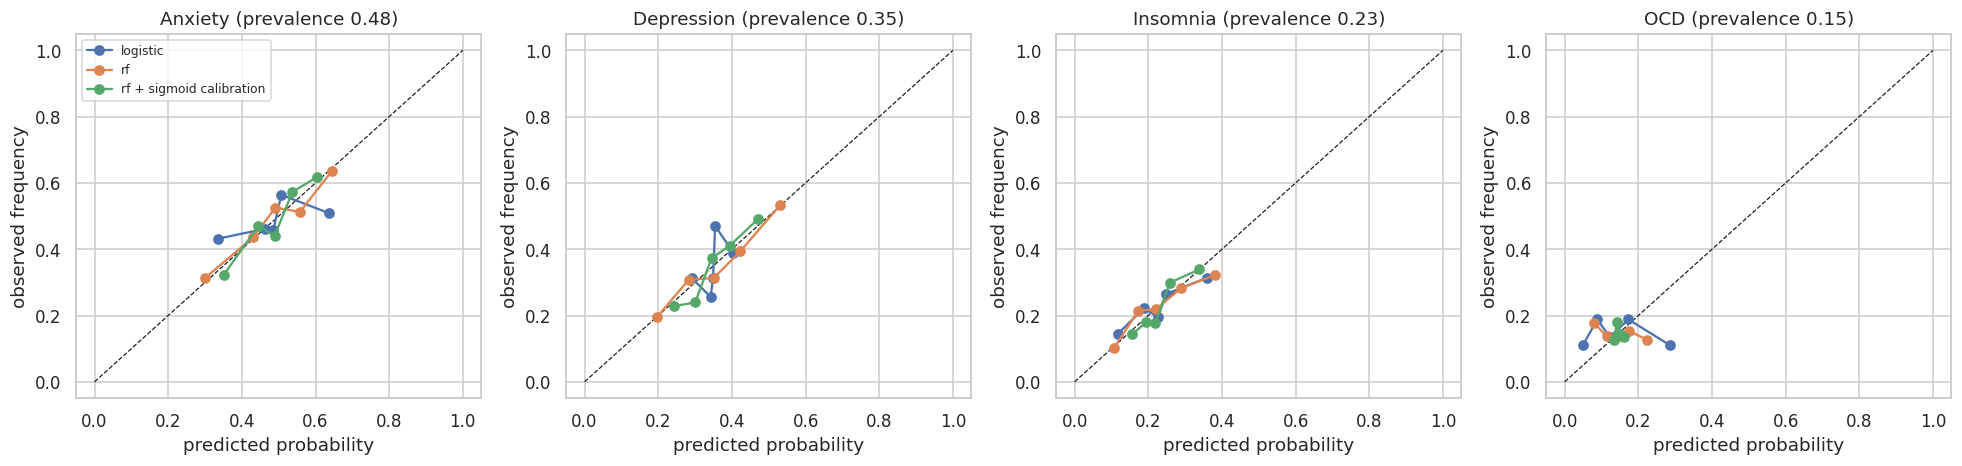

target,Anxiety,Depression,Insomnia,OCD
model,,,,
logistic,-0.014,0.010,0.013,-0.082
rf,0.039,0.044,0.024,-0.034
rf + sigmoid calibration,0.047,0.036,0.019,-0.002


In [12]:
cols = FEATURE_SETS['habits + genres']
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {'logistic': classifiers()['logistic'], 'rf': classifiers()['rf'],
          'rf + sigmoid calibration': CalibratedClassifierCV(classifiers()['rf'], method='sigmoid', cv=5)}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4)); rows = []
oof = {}
for ax, t in zip(axes, TARGETS):
    y = train[f'{t}_high']; prev = y.mean()
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    for name, mdl in models.items():
        pr = cross_val_predict(make_pipeline(cols, mdl), train[cols], y, cv=skf, method='predict_proba')[:, 1]
        oof[(t, name)] = pr
        fo, mp = calibration_curve(y, pr, n_bins=5, strategy='quantile')
        ax.plot(mp, fo, 'o-', label=name)
        bs = brier_score_loss(y, pr); bs0 = brier_score_loss(y, np.full(len(y), prev))
        rows.append({'target': t, 'model': name, 'brier': bs, 'brier_skill': 1 - bs / bs0, 'auroc': roc_auc_score(y, pr)})
    ax.set_title(f'{t} (prevalence {prev:.2f})'); ax.set_xlabel('predicted probability'); ax.set_ylabel('observed frequency')
axes[0].legend(fontsize=8); plt.tight_layout(); fig.savefig(FIG / 'calibration.png', dpi=150); plt.show()
calib = pd.DataFrame(rows); calib.round(4).to_csv(TAB / 'calibration_metrics.csv', index=False)
display(calib.pivot(index='model', columns='target', values='brier_skill').round(3))

## 6. Does performance hold across subgroups?

A model that works on average but fails for adolescents or for light listeners would be misleading to researchers. Out-of-fold logistic-regression AUROC by subgroup (groups with fewer than 10 positives or negatives are omitted).

,target,group_var,group,n,auroc,ci_lo,ci_hi
0,Depression,age_group,<18,116,0.570,0.444,0.697
1,Depression,age_group,18-24,271,0.575,0.503,0.643
2,Depression,age_group,25-34,120,0.489,0.381,0.595
3,Depression,age_group,35+,80,0.619,0.437,0.779
4,Depression,hours_group,<=2 h,269,0.550,0.477,0.619
5,Depression,hours_group,2-4 h,169,0.572,0.479,0.666
6,Depression,hours_group,>4 h,146,0.515,0.426,0.603
7,Depression,instrumentalist,no instrument,404,0.565,0.505,0.624
8,Depression,instrumentalist,plays instrument,181,0.588,0.498,0.670
9,Anxiety,age_group,<18,116,0.531,0.423,0.636


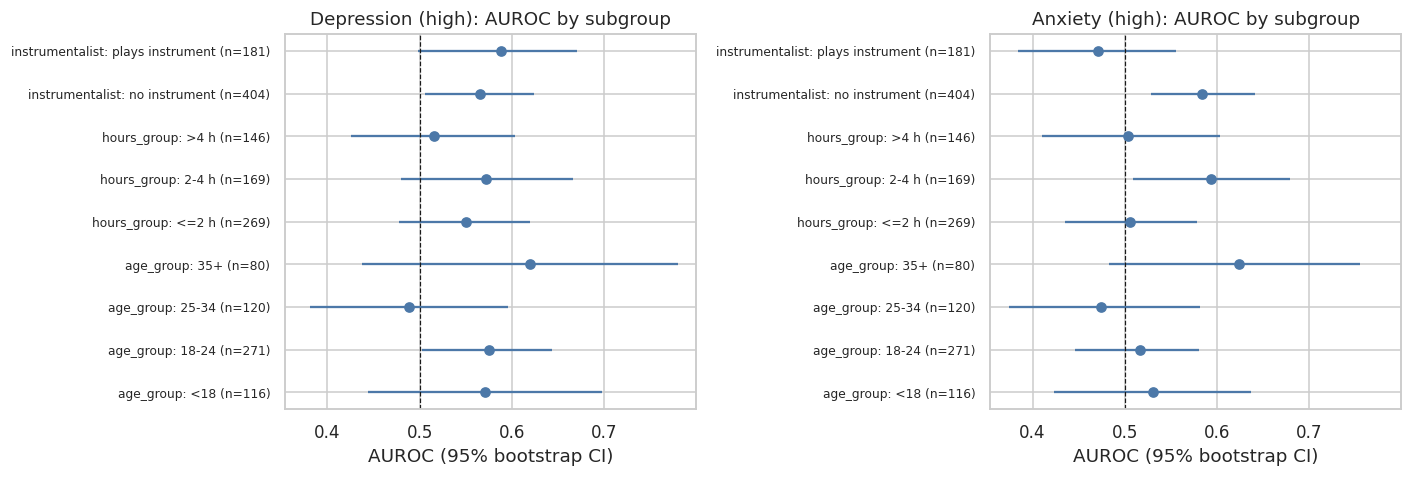

In [13]:
sub = train.copy()
sub['hours_group'] = pd.cut(sub['hours'], [-0.1, 2, 4, 16], labels=['<=2 h', '2-4 h', '>4 h'])
sub['instrumentalist'] = sub['Instrumentalist'].map({1: 'plays instrument', 0: 'no instrument'})
rows = []
for t in ('Depression', 'Anxiety'):
    y = sub[f'{t}_high'].values; pr = oof[(t, 'logistic')]
    for gcol in ('age_group', 'hours_group', 'instrumentalist'):
        for g, idx in sub.groupby(gcol, observed=True).groups.items():
            idx = np.asarray(idx)
            if min(y[idx].sum(), (1 - y[idx]).sum()) < 10: continue
            a, lo, hi = bootstrap_metric(y[idx], pr[idx], roc_auc_score)
            rows.append({'target': t, 'group_var': gcol, 'group': str(g), 'n': len(idx), 'auroc': a, 'ci_lo': lo, 'ci_hi': hi})
subg = pd.DataFrame(rows); subg.round(3).to_csv(TAB / 'subgroup_auroc.csv', index=False); display(subg.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, t in zip(axes, ('Depression', 'Anxiety')):
    d = subg[subg.target == t].reset_index(drop=True)
    ax.errorbar(d.auroc, range(len(d)), xerr=[d.auroc - d.ci_lo, d.ci_hi - d.auroc], fmt='o', color='#4C78A8')
    ax.axvline(0.5, color='k', ls='--', lw=0.8); ax.set_yticks(range(len(d)))
    ax.set_yticklabels([f'{r.group_var}: {r.group} (n={r.n})' for r in d.itertuples()], fontsize=8)
    ax.set_title(f'{t} (high): AUROC by subgroup'); ax.set_xlabel('AUROC (95% bootstrap CI)')
plt.tight_layout(); fig.savefig(FIG / 'subgroup_auroc.png', dpi=150); plt.show()

## 7. Which features carry stable signal?

Permutation importance (drop in validation-fold R² when one feature is shuffled) computed on each of 10 validation folds, for the ridge model (primary) and a random forest (check). A feature counts as **stable** only if its mean importance is positive and it is positive in ≥ 80% of folds, since a single-split importance can be pure noise.

In [14]:
cols = FEATURE_SETS['habits + genres']
kf = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
recs = []
t0 = time.time()
for t in TARGETS:
    for mname in ('ridge', 'rf'):
        for fold, (tr, va) in enumerate(kf.split(train)):
            pipe = make_pipeline(cols, regressors()[mname]).fit(train.iloc[tr][cols], train.iloc[tr][t])
            pi = permutation_importance(pipe, train.iloc[va][cols], train.iloc[va][t], scoring='r2',
                                        n_repeats=5, random_state=SEED, n_jobs=1)
            for f, v in zip(cols, pi.importances_mean):
                recs.append({'target': t, 'model': mname, 'fold': fold, 'feature': f, 'importance': v})
imp = pd.DataFrame(recs)
agg = imp.groupby(['target', 'model', 'feature']).importance.agg(mean='mean', sd='std', frac_pos=lambda s: (s > 0).mean()).reset_index()
agg['stable'] = (agg['mean'] > 0) & (agg['frac_pos'] >= 0.8)
agg.round(5).to_csv(TAB / 'permutation_importance.csv', index=False)
print(f'done in {time.time() - t0:.0f}s')
print('Stable features (ridge):')
display(agg[(agg.model == 'ridge') & agg.stable].sort_values(['target', 'mean'], ascending=[True, False]).round(4).reset_index(drop=True))
print('Stable features (random forest):')
display(agg[(agg.model == 'rf') & agg.stable].sort_values(['target', 'mean'], ascending=[True, False]).round(4).reset_index(drop=True))

done in 95s
Stable features (ridge):


,target,model,feature,mean,sd,frac_pos,stable
0,Anxiety,ridge,Age,0.0243,0.0163,0.9,True
1,Anxiety,ridge,freq_Folk,0.0158,0.0129,0.9,True
2,Anxiety,ridge,Exploratory,0.0041,0.0035,0.9,True
3,Anxiety,ridge,freq_Video game music,0.0030,0.0083,0.8,True
4,Anxiety,ridge,freq_Pop,0.0023,0.0051,0.8,True
5,Anxiety,ridge,freq_Rock,0.0017,0.0023,0.9,True
6,Anxiety,ridge,freq_Latin,0.0001,0.0030,0.8,True
7,Depression,ridge,freq_Rock,0.0194,0.0093,1.0,True
8,Depression,ridge,freq_Folk,0.0150,0.0095,1.0,True
9,Depression,ridge,Age,0.0079,0.0129,0.8,True


Stable features (random forest):


,target,model,feature,mean,sd,frac_pos,stable
0,Anxiety,rf,Age,0.0959,0.0398,1.0,True
1,Anxiety,rf,freq_Folk,0.0258,0.0145,1.0,True
2,Anxiety,rf,Hours per day,0.0044,0.0188,0.8,True
3,Anxiety,rf,freq_Metal,0.0033,0.0024,0.8,True
4,Anxiety,rf,Composer,0.0008,0.0016,0.8,True
5,Depression,rf,Age,0.0300,0.0156,1.0,True
6,Depression,rf,freq_Metal,0.0062,0.0068,0.9,True
7,Depression,rf,freq_Rock,0.0057,0.0110,0.8,True
8,Depression,rf,freq_Lofi,0.0009,0.0021,0.8,True
9,Insomnia,rf,Hours per day,0.0317,0.0184,0.9,True


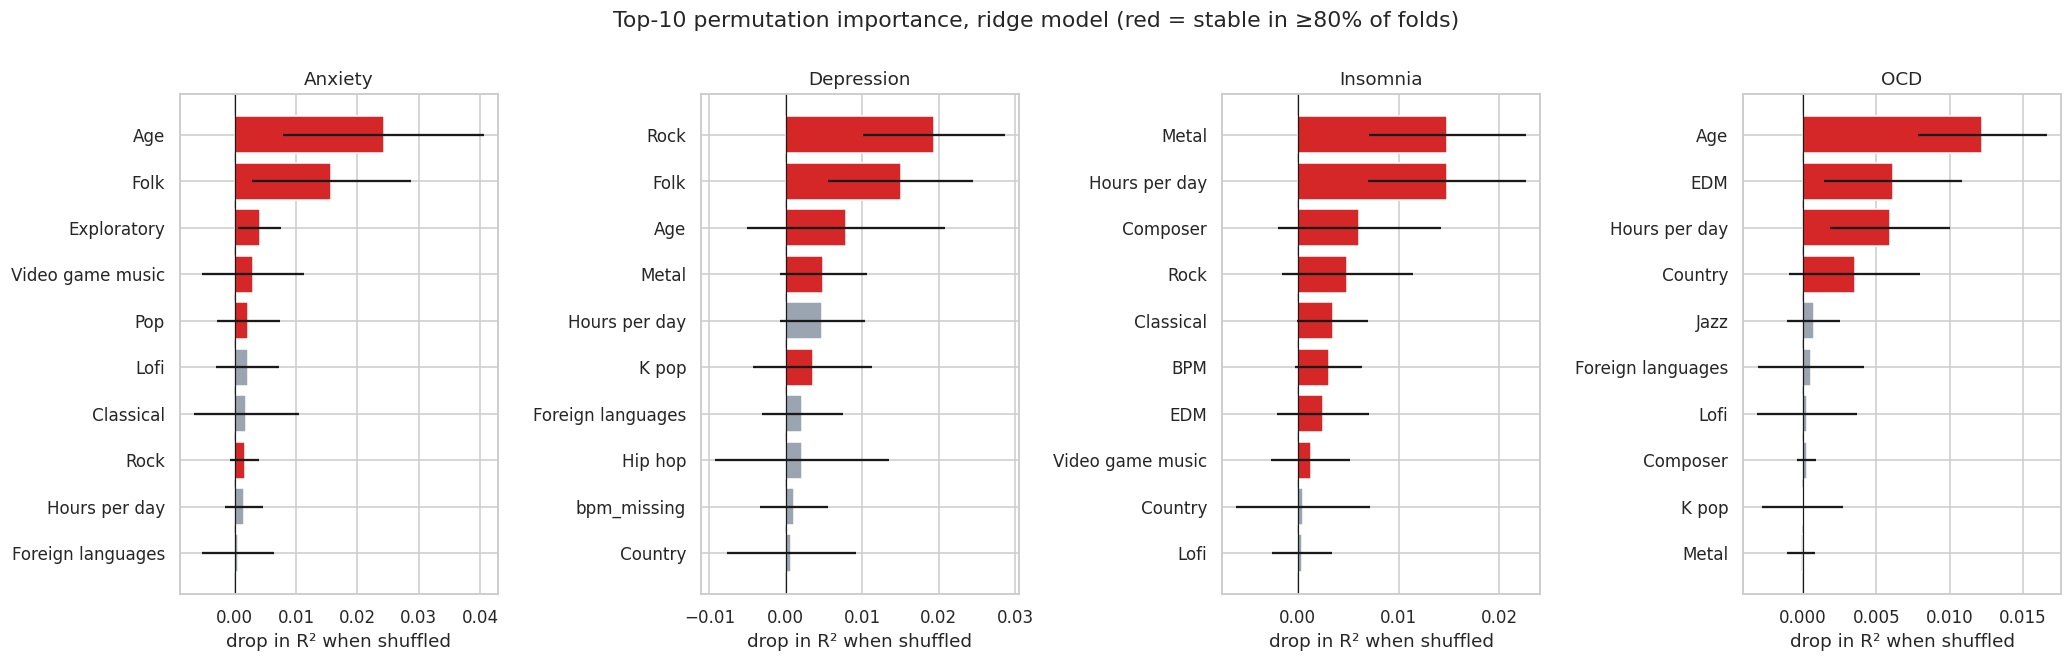

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(19, 6))
for ax, t in zip(axes, TARGETS):
    d = agg[(agg.target == t) & (agg.model == 'ridge')].sort_values('mean', ascending=False).head(10).iloc[::-1]
    ax.barh(d.feature.str.replace('freq_', ''), d['mean'], xerr=d.sd, color=np.where(d.stable, '#D62728', '#9AA5B1'))
    ax.axvline(0, color='k', lw=0.8); ax.set_title(f'{t}'); ax.set_xlabel('drop in R² when shuffled')
plt.suptitle('Top-10 permutation importance, ridge model (red = stable in ≥80% of folds)', y=1.0)
plt.tight_layout(); fig.savefig(FIG / 'permutation_importance.png', dpi=150); plt.show()

### SHAP: direction and shape of the effects

SHAP values from a random forest fitted on the training data, evaluated on the hold-out respondents. Unlike permutation importance, they show the **direction** (does higher frequency push the predicted score up or down?).

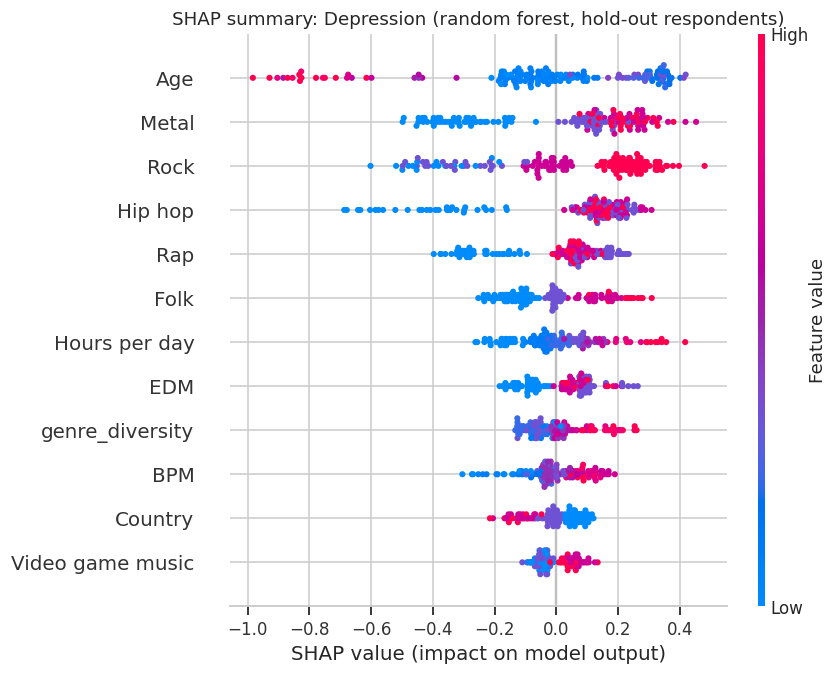

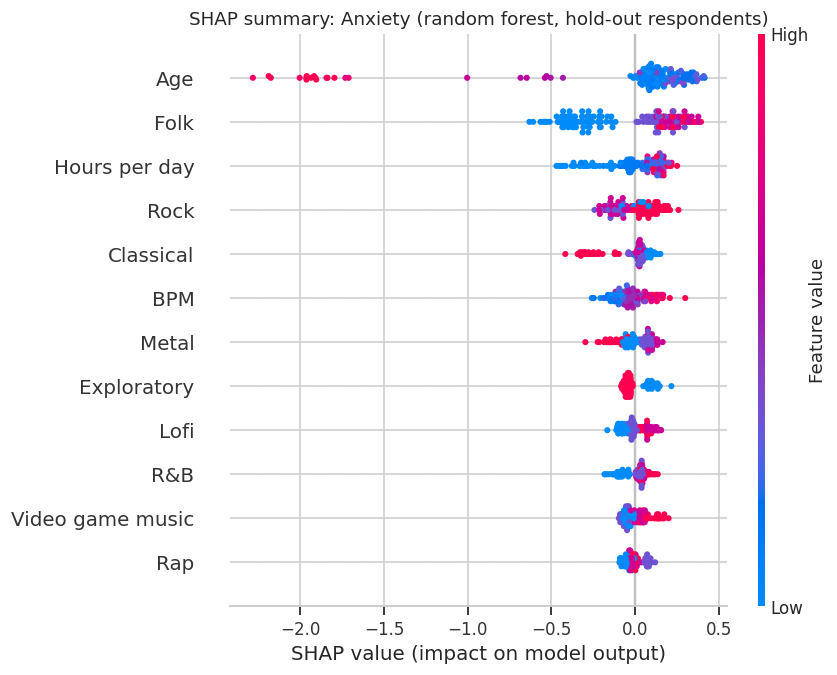

In [16]:
try:
    import shap
    prep = make_preprocessor(cols).fit(train[cols])
    Xtr = pd.DataFrame(prep.transform(train[cols]), columns=prep.get_feature_names_out())
    Xte = pd.DataFrame(prep.transform(test[cols]), columns=prep.get_feature_names_out())
    Xte.columns = Xtr.columns = [c.replace('freq_', '') for c in Xtr.columns]
    for t in ('Depression', 'Anxiety'):
        rf = regressors()['rf'].fit(Xtr, train[t])
        sv = shap.TreeExplainer(rf).shap_values(Xte, check_additivity=False)
        plt.figure(); shap.summary_plot(sv, Xte, max_display=12, show=False)
        plt.title(f'SHAP summary: {t} (random forest, hold-out respondents)')
        plt.tight_layout(); plt.savefig(FIG / f'shap_{t.lower()}.png', dpi=150, bbox_inches='tight'); plt.show()
except ImportError:
    print('shap is not installed; run `pip install shap` to reproduce this figure.')

## 8. Evidence synthesis: a ranked hypothesis list for follow-up research

Each genre-condition pair earns one point for each independent line of evidence:

1. **Raw association** is significant after FDR correction (notebook 01).
2. **Adjusted association** (controlling for age, hours, instrument playing and the other genres) has nominal p < 0.05 with the same sign as the raw association.
3. **Predictive stability**: the genre is a stable feature in the ridge permutation analysis for that condition.

3 points = **A (replicate first)**, 2 = **B (promising)**, 1 = **C (exploratory)**. This is a transparent triage rule for choosing what a clinical research team should test, not a statement that any effect is causal.

In [17]:
eff = pd.read_csv(TAB / 'genre_condition_effects.csv')
adj = pd.read_csv(TAB / 'genre_condition_adjusted.csv')
stab = agg[agg.model == 'ridge'][['target', 'feature', 'stable', 'mean']].rename(columns={'target': 'condition', 'mean': 'perm_importance'})
stab['genre'] = stab.feature.str.replace('freq_', '')
stab = stab[stab.genre.isin(GENRES)]
rk = (eff[['genre', 'condition', 'rho', 'ci_lo', 'ci_hi', 'q_fdr']]
      .merge(adj[['genre', 'condition', 'coef', 'p']].rename(columns={'coef': 'adj_coef', 'p': 'adj_p'}), on=['genre', 'condition'])
      .merge(stab[['genre', 'condition', 'stable', 'perm_importance']], on=['genre', 'condition']))
rk['ev_raw'] = (rk.q_fdr < 0.05).astype(int)
rk['ev_adjusted'] = ((rk.adj_p < 0.05) & (np.sign(rk.adj_coef) == np.sign(rk.rho))).astype(int)
rk['ev_stable'] = rk.stable.astype(int)
rk['points'] = rk[['ev_raw', 'ev_adjusted', 'ev_stable']].sum(axis=1)
rk['direction'] = np.where(rk.rho > 0, 'higher listening <-> higher score', 'higher listening <-> lower score')
rk['tier'] = rk.points.map({3: 'A: replicate first', 2: 'B: promising', 1: 'C: exploratory', 0: 'none'})
rk = rk.sort_values(['points', 'rho'], key=lambda s: s if s.name == 'points' else s.abs(), ascending=False).reset_index(drop=True)
rk.round(4).to_csv(TAB / 'hypothesis_ranking.csv', index=False)
print('Tier counts:', rk.tier.value_counts().to_dict())
display(rk[rk.points >= 1][['genre', 'condition', 'rho', 'ci_lo', 'ci_hi', 'adj_coef', 'adj_p', 'ev_raw', 'ev_adjusted', 'ev_stable', 'tier', 'direction']].round(3))

Tier counts: {'none': 42, 'C: exploratory': 13, 'B: promising': 5, 'A: replicate first': 4}


,genre,condition,rho,ci_lo,ci_hi,adj_coef,adj_p,ev_raw,ev_adjusted,ev_stable,tier,direction
0,Rock,Depression,0.184,0.108,0.257,0.330,0.022,1,1,1,A: replicate first,higher listening <-> higher score
1,Metal,Insomnia,0.160,0.087,0.233,0.367,0.003,1,1,1,A: replicate first,higher listening <-> higher score
2,Folk,Anxiety,0.106,0.038,0.175,0.305,0.012,1,1,1,A: replicate first,higher listening <-> higher score
3,EDM,OCD,0.101,0.027,0.172,0.216,0.048,1,1,1,A: replicate first,higher listening <-> higher score
4,Metal,Depression,0.189,0.121,0.260,0.242,0.053,1,0,1,B: promising,higher listening <-> higher score
5,Folk,Depression,0.110,0.040,0.180,0.238,0.069,1,0,1,B: promising,higher listening <-> higher score
6,Rock,Anxiety,0.107,0.033,0.180,0.072,0.609,1,0,1,B: promising,higher listening <-> higher score
7,Video game music,Anxiety,0.101,0.026,0.173,0.143,0.196,1,0,1,B: promising,higher listening <-> higher score
8,Pop,Anxiety,0.087,0.015,0.159,0.265,0.045,0,1,1,B: promising,higher listening <-> higher score
9,Rap,Depression,0.138,0.064,0.213,0.216,0.238,1,0,0,C: exploratory,higher listening <-> higher score


## 9. Headline numbers

In [18]:
print('Personas: k =', best_k, '| silhouette', ktab.set_index('k').loc[best_k, 'silhouette'].round(3),
      '| stability ARI', ktab.set_index('k').loc[best_k, 'stability_ARI'].round(3), '(weak structure)' if weak else '')
print('Persona tests (FDR-adjusted, age/hours-controlled):'); display(pers[['condition', 'epsilon_sq', 'q_fdr_raw', 'q_fdr_adjusted']].round(4))
best = ho[(ho.feature_set == 'habits + genres') & (ho.model.isin(['ridge', 'logistic']))][['target', 'metric', 'value', 'ci_lo', 'ci_hi']]
print('Hold-out, primary model, habits + genres:'); display(best.round(3))
print('Hypotheses by tier:', rk.tier.value_counts().to_dict())

Personas: k = 3 | silhouette 0.117 | stability ARI 0.817 
Persona tests (FDR-adjusted, age/hours-controlled):


,condition,epsilon_sq,q_fdr_raw,q_fdr_adjusted
0,Anxiety,0.0082,0.0239,0.0077
1,Depression,0.0235,0.0003,0.0005
2,Insomnia,0.0139,0.0044,0.0079
3,OCD,-0.0010,0.5251,0.4499


Hold-out, primary model, habits + genres:


,target,metric,value,ci_lo,ci_hi
4,Anxiety,R2,-0.014,-0.115,0.059
6,Anxiety,AUROC,0.486,0.394,0.583
16,Depression,R2,0.031,-0.061,0.108
18,Depression,AUROC,0.570,0.472,0.669
28,Insomnia,R2,-0.020,-0.126,0.044
30,Insomnia,AUROC,0.512,0.395,0.626
40,OCD,R2,0.007,-0.063,0.049
42,OCD,AUROC,0.524,0.351,0.688


Hypotheses by tier: {'none': 42, 'C: exploratory': 13, 'B: promising': 5, 'A: replicate first': 4}


## 10. Interpretation and limits (read before citing any result)

- **Association, not causation.** Cross-sectional self-report cannot separate music shaping mood from mood shaping music choice. Treat every effect as a hypothesis.
- **Not clinical measurements.** The 0–10 scores are single self-ratings, not validated instruments (e.g. PHQ-9, GAD-7, ISI, OCI-R). Any model here is **not a screening or diagnostic tool**.
- **Self-selected sample.** Respondents came from an online survey, so prevalence and effect sizes will not generalise to a clinical population. 153 respondents are under 18; subgroup results are shown but not powered for firm conclusions.
- **Small n.** With 736 respondents (588 for training, 148 for testing), small effects are hard to pin down and rare genres are too thin to interpret.
- **Multiple testing.** FDR correction is applied throughout, but the hypothesis list is still a *triage*, not confirmation.

**What a medical research group could do with this**
1. Pre-register the Tier A/B hypotheses and test them on a new sample with validated clinical scales.
2. Collect longitudinal or experimental data (for example, randomised listening conditions) to address direction of effect.
3. Record listening **context and motivation** (coping, mood regulation), which this survey lacks and which probably explains more than genre.